In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.coordinates as coord
import astropy.units as u
from astropy.coordinates import angular_separation as ang
import matplotlib
plt.style.use(['science','notebook','grid'])
plt.rcParams["font.family"] = "serif"
#df=pd.read_csv("../Untitled Folder/Pantheon+SH0ES.csv",header=0,delimiter=" ")
df=pd.read_csv("Pantheon+SH0ES.csv",header=0,delimiter=" ")
dict2={}
dict1={}
un=np.load('unique.npy')
df=df.iloc[un]
%run  Angluar_tools.ipynb
for Id in [1,4,5,10,15,18,50,51,56,57,61,62,63,64,65,66,100,101,106,150]:
    dict1[Id]= SkyCoord(df['RA'][df['IDSURVEY']==Id],df["DEC"][df['IDSURVEY']==Id],unit=u.deg)
    dict2[Id]=dict1[Id].galactic

fmt2={1:'X',2:'o',3:'|',4:'*',5:'v', 10:'1', 15:'s', 18: 'D', 50:'^', 51:'+', 56:'h', 57: '8', 61:'3', 62:'4', 63:'P', 64:'x' ,65:'>', 66:'<', 100:'*', 101:'o', 106:'_', 150:'v'}
c2={1:'k',2:'o',3:'firebrick',4:'orangered',5:'darkorange', 10:'forestgreen', 15:'r', 18: 'lightseagreen', 50:'royalblue', 51:'slategrey', 56:'chocolate', 57: 'chartreuse', 61:'fuchsia', 62:'darkkhaki', 63:'maroon', 64:'purple' ,65:'steelblue', 66:'seagreen', 100:'blueviolet', 101:'aquamarine', 106:'midnightblue', 150:'green'}

k={1:'SDSS', 4:'SNLS', 5:'CSP', 10:'DES', 15:'PS1MD', 18: 'CNIa0.02', 50:'LOWZ/JRK07', 51:'LOSS1', 56:'SOUSA', 57: 'LOSS2 ', 61:'CFA1', 62:'CFA2', 63:'CFA3S', 64:'CFA3K' ,65:'CFA4p2', 66:'CFA4p3', 100:'HST', 101:'SNAP', 106:'CANDELS', 150:'FOUND'}



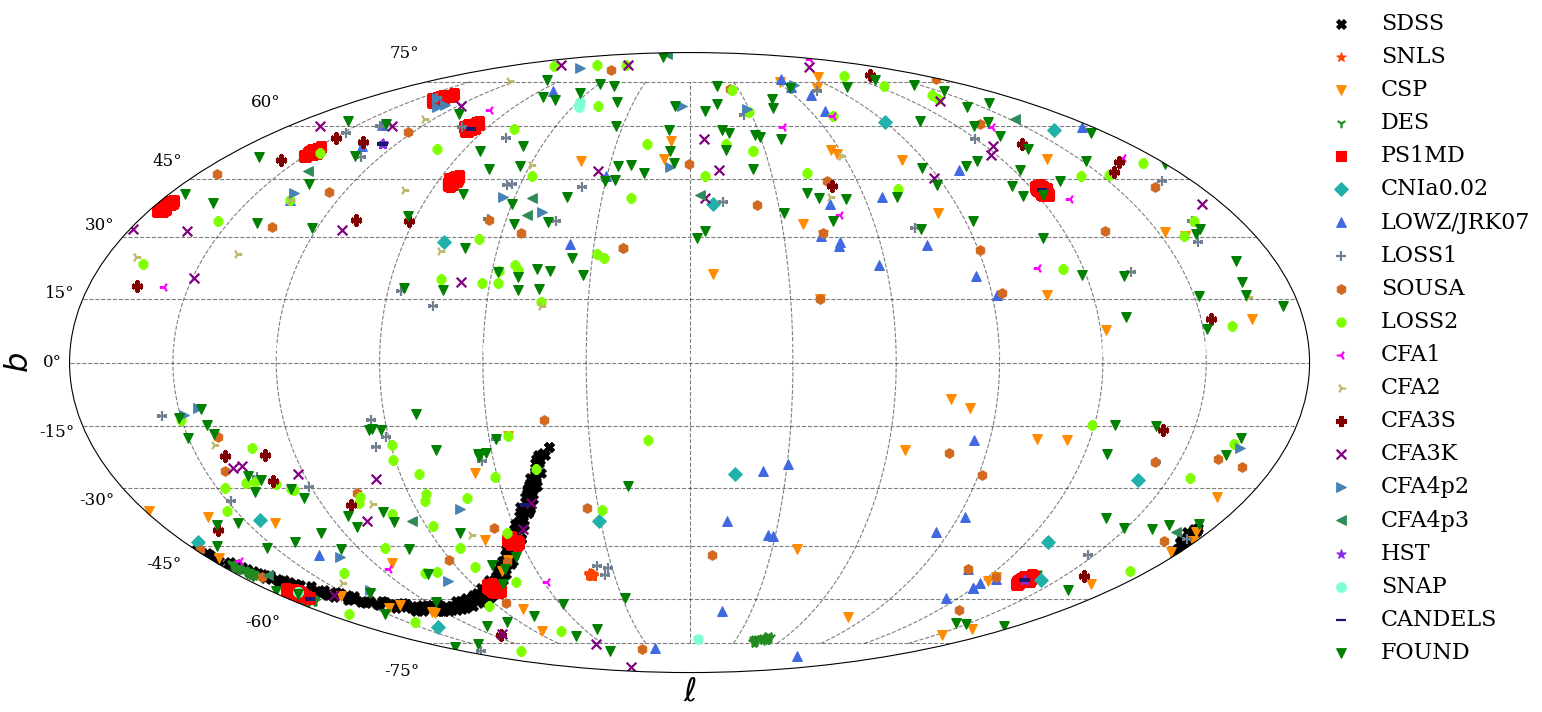

In [3]:
dict2={}
dict1={}
for Id in [1,4,5,10,15,18,50,51,56,57,61,62,63,64,65,66,100,101,106,150]:
    dict1[Id]= SkyCoord(df['RA'][df['IDSURVEY']==Id],df["DEC"][df['IDSURVEY']==Id],unit=u.deg)
    dict2[Id]=dict1[Id].galactic
tick_labels = np.array([150, 120, 90, 60, 30, 0, 330, 300, 270, 240, 210])
org = 0
tick_labels = np.remainder(tick_labels+360+org,360)
fig = plt.figure(figsize=(20, 15))
#ax.plot(galpan.l.wrap_at('180d').radian, galpan.b.radian,"gv",ms=10,label='PAN+ (JLA $\cap$ PAN+)')

ax = fig.add_subplot(111, projection='mollweide')
ax.set_xticklabels(tick_labels)

ax.tick_params(axis='x', colors='white')
fmt2={1:'X',2:'o',3:'|',4:'*',5:'v', 10:'1', 15:'s', 18: 'D', 50:'^', 51:'+', 56:'h', 57: '8', 61:'3', 62:'4', 63:'P', 64:'x' ,65:'>', 66:'<', 100:'*', 101:'o', 106:'_', 150:'v'}
c2={1:'k',2:'o',3:'firebrick',4:'orangered',5:'darkorange', 10:'forestgreen', 15:'r', 18: 'lightseagreen', 50:'royalblue', 51:'slategrey', 56:'chocolate', 57: 'chartreuse', 61:'fuchsia', 62:'darkkhaki', 63:'maroon', 64:'purple' ,65:'steelblue', 66:'seagreen', 100:'blueviolet', 101:'aquamarine', 106:'midnightblue', 150:'green'}

k={1:'SDSS', 4:'SNLS', 5:'CSP', 10:'DES', 15:'PS1MD', 18: 'CNIa0.02', 50:'LOWZ/JRK07', 51:'LOSS1', 56:'SOUSA', 57: 'LOSS2 ', 61:'CFA1', 62:'CFA2', 63:'CFA3S', 64:'CFA3K' ,65:'CFA4p2', 66:'CFA4p3', 100:'HST', 101:'SNAP', 106:'CANDELS', 150:'FOUND'}
for Id in [1,4,5,10,15,18,50,51,56,57,61,62,63,64,65,66,100,101,106,150]:
    #plt.plot(dict2[Id].l.wrap_at('180d').radian, dict2[Id].b.radian,fmt2[Id],label=k[Id])
    plot_oneset(ax, dict2[Id].l.value,dict2[Id].b.value ,color=c2[Id], marker=fmt2[Id], size=75, fillstyle='none', line=False, alpha=1,l1=k[Id])
plt.savefig('Unique_skymap.pdf')

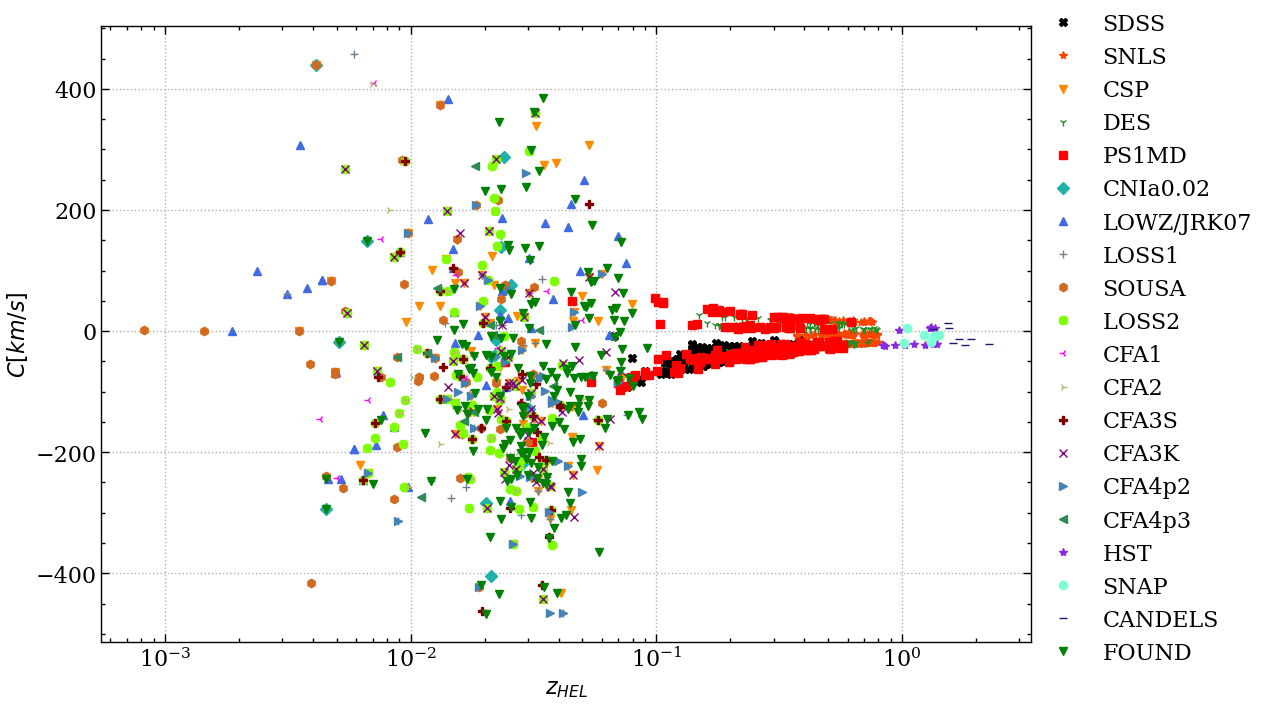

In [13]:
vcmb=369.82 #km/s
c=299792.458
racmb=np.deg2rad(167.94)
deccmb=np.deg2rad(-6.94)
rapan=np.deg2rad(df['RA'])
decpan=np.deg2rad(df['DEC'])

cosangle=np.cos(np.array(ang(racmb,deccmb,rapan,decpan)))
zd=np.sqrt((1-vcmb*cosangle/c)/(1+vcmb*cosangle/c))-1

C=((1+df['zHEL'])-(1+df['zHD'])*(1+zd))*c


plt.figure(figsize=(12,8))
for Id in [1,4,5,10,15,18,50,51,56,57,61,62,63,64,65,66,100,101,106,150]:
    plt.plot(df['zHEL'][df['IDSURVEY']==Id],C[df['IDSURVEY']==Id],marker=fmt2[Id],ls='None',color=c2[Id],label=k[Id])
plt.xscale('log')

plt.grid(ls=':')
plt.ylabel('$C[km/s]$')
plt.xlabel('$z_{HEL}$')

plt.legend(loc=(1,-0.05))
plt.savefig('C_corr.pdf')

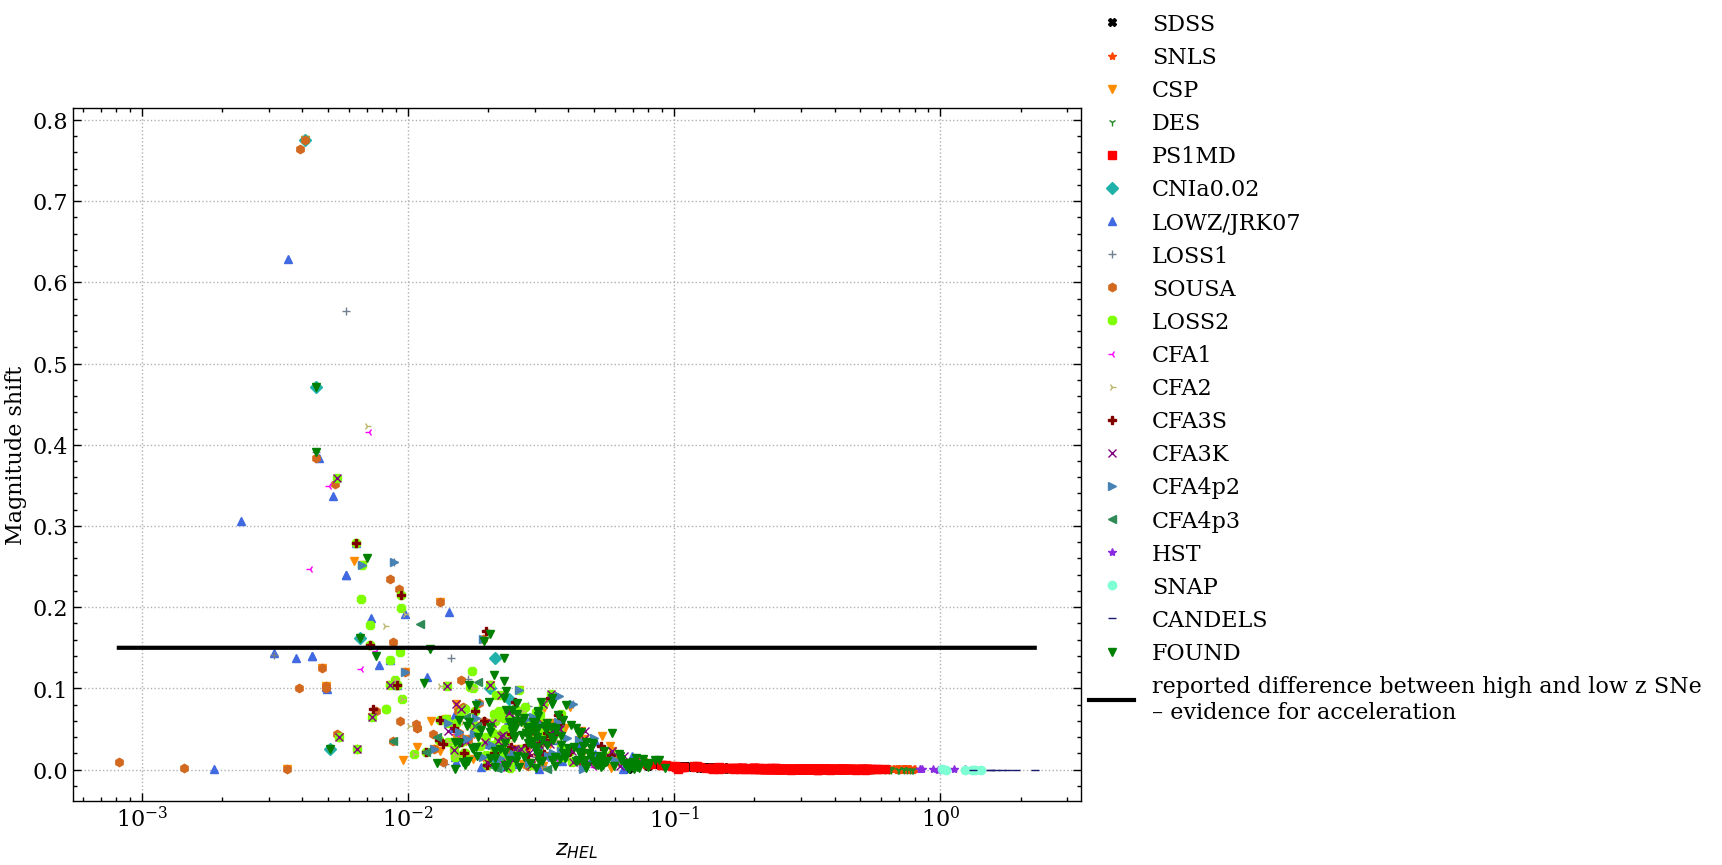

In [130]:
y_val=abs((5/np.log(10))*C/(df['zHEL']*c))
plt.figure(figsize=(13,9))

for Id in [1,4,5,10,15,18,50,51,56,57,61,62,63,64,65,66,100,101,106,150]:
    plt.plot(df['zHEL'][df['IDSURVEY']==Id],y_val[df['IDSURVEY']==Id],marker=fmt2[Id],ls='None',color=c2[Id],label=k[Id])
plt.xscale('log')
plt.grid(ls=':')
plt.ylabel('Magnitude shift')
plt.xlabel('$z_{HEL}$')
plt.plot(df['zHEL'],0.15*np.ones(len(df['zHEL'])),'k',lw=3,label='reported difference between high and low z SNe \n– evidence for acceleration')
plt.legend(loc=(1,0.1))

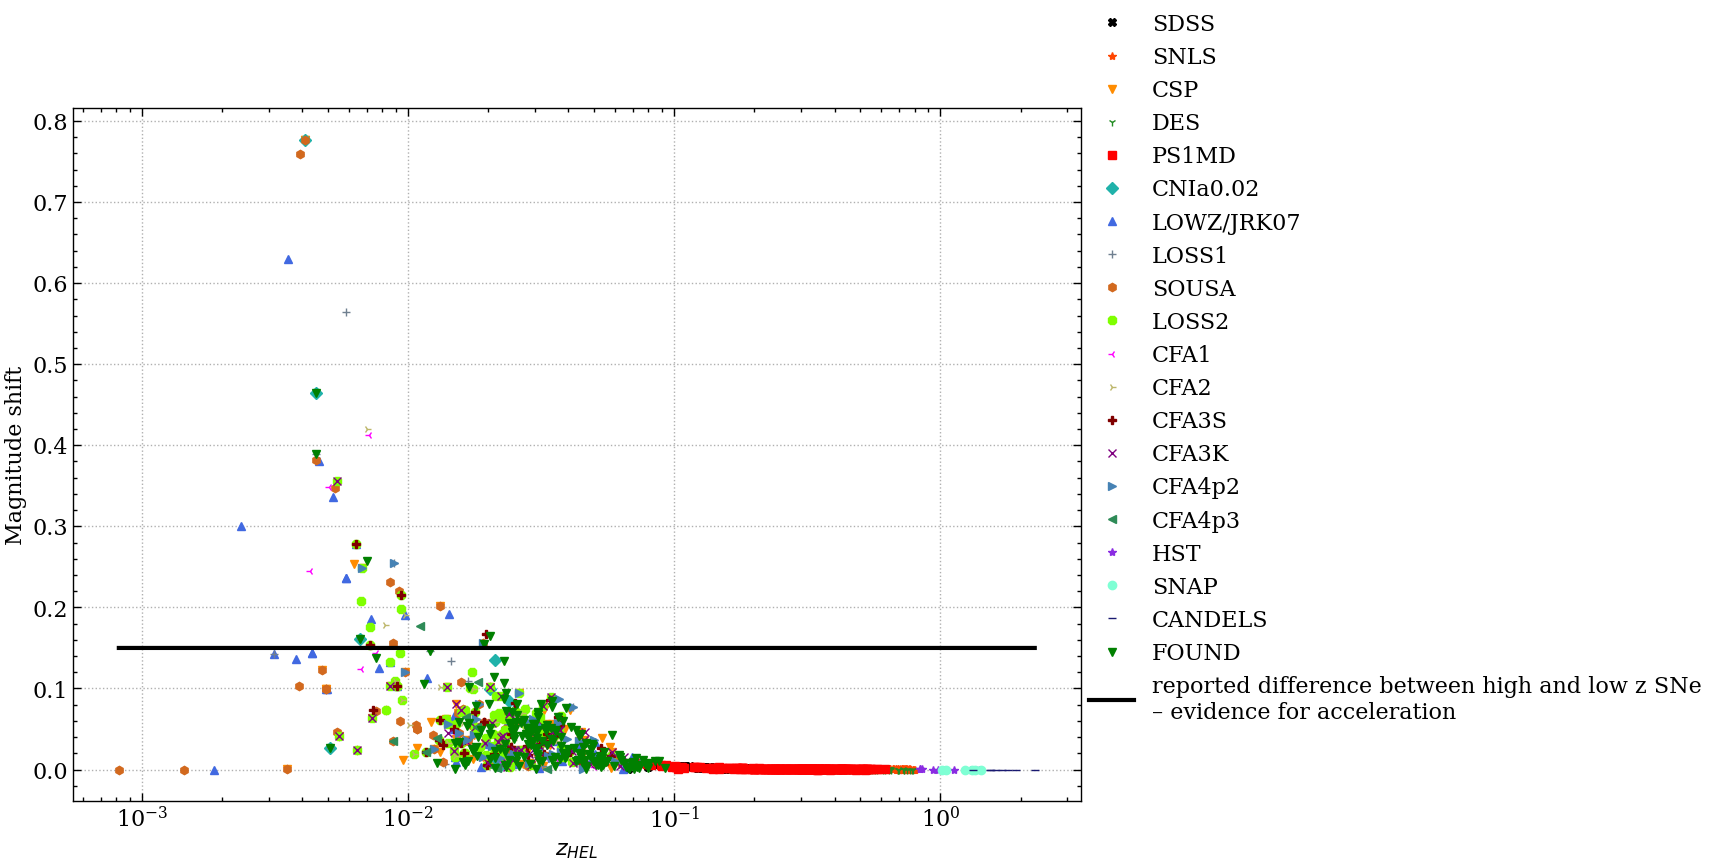

In [147]:
y_val2=abs((5/np.log(10))*df['VPEC']/(df['zHEL']*c))
plt.figure(figsize=(13,9))

for Id in [1,4,5,10,15,18,50,51,56,57,61,62,63,64,65,66,100,101,106,150]:
    plt.plot(df['zHEL'][df['IDSURVEY']==Id],y_val2[df['IDSURVEY']==Id],marker=fmt2[Id],ls='None',color=c2[Id],label=k[Id])
plt.xscale('log')
plt.grid(ls=':')
plt.ylabel('Magnitude shift')
plt.xlabel('$z_{HEL}$')
plt.plot(df['zHEL'],0.15*np.ones(len(df['zHEL'])),'k',lw=3,label='reported difference between high and low z SNe \n– evidence for acceleration')
plt.legend(loc=(1,0.1))

<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:11: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_4981/1018277758.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel('$\Delta \mu$')
/tmp/ipykernel_4981/1018277758.py:11: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('$\mathrm{z_{HEL}}$')


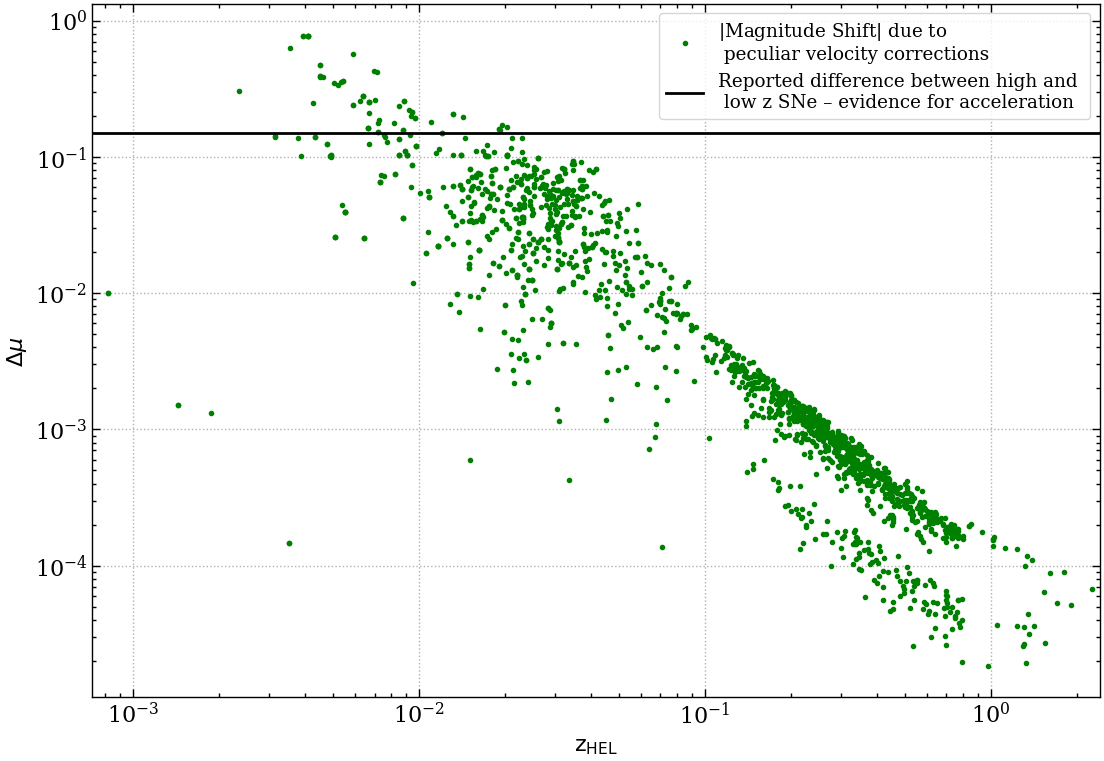

In [9]:
y_val=abs((5/np.log(10))*C/(df['zHEL']*c))
plt.figure(figsize=(13,9))

plt.plot(df['zHEL'],y_val,ls='None',marker='.',color='g',label='$|$Magnitude Shift$|$ due to \n peculiar velocity corrections')

#plt.plot(df['zHEL'],y_val2,ls='None',marker='.',color='k')
zhel=np.linspace(0.00072,2.4,10)
plt.xscale('log')
plt.grid(ls=':')
plt.ylabel('$\Delta \mu$')
plt.xlabel('$\mathrm{z_{HEL}}$')
plt.plot(zhel,0.15*np.ones(10),'k',lw=2,label='Reported difference between high and \n low z SNe – evidence for acceleration')
plt.legend(frameon=True,fontsize=13.2)
plt.xlim(0.00072,2.4)
plt.yscale('log')
#plt.text(0.001,0.00002,'Preliminary results',color='red',fontsize=14)
plt.savefig('Magnitude_shift.pdf')

In [58]:
df['zHD']

0       0.00122
1       0.00122
2       0.00256
3       0.00256
4       0.00299
         ...   
1696    1.61505
1697    1.69706
1698    1.80119
1699    1.91165
1700    2.26137
Name: zHD, Length: 1701, dtype: float64

In [80]:
cosangle2

0       0.326971
1       0.326971
2       0.906916
3       0.906916
4       0.904808
          ...   
1696    0.308168
1697   -0.895593
1698    0.323032
1699   -0.669329
1700    0.323036
Length: 1701, dtype: float64

In [81]:
cosangle

array([-0.17142643, -0.17142643, -0.99311464, ..., -0.62800394,
       -0.09269122, -0.55470497])

In [85]:
ang(racmb,deccmb,rapan,decpan)

0       1.743074
1       1.743074
2       3.024176
3       3.024176
4       1.713172
          ...   
1696    0.474739
1697    2.673350
1698    2.249782
1699    1.663621
1700    2.158805
Length: 1701, dtype: float64

In [91]:
ang(racmb,deccmb,rapan,decpan)

0       1.743074
1       1.743074
2       3.024176
3       3.024176
4       1.713172
          ...   
1696    0.474739
1697    2.673350
1698    2.249782
1699    1.663621
1700    2.158805
Length: 1701, dtype: float64

In [94]:
ang(racmb,deccmb,rapan,decpan))

array([ 0.32697067,  0.32697067,  0.90691616, ...,  0.32303239,
       -0.66932863,  0.32303588])

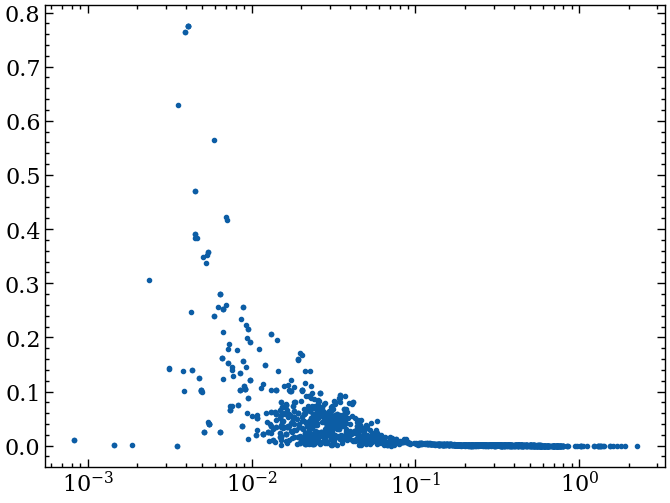

In [165]:
plt.plot(df['zHEL'],abs(2.1714724095162588*C/(df['zHEL']*c)),'.')
plt.xscale('log')

In [163]:
5/np.log(10)

2.1714724095162588

In [185]:
vcmb=369.82 #km/s
c=299792.458
racmb=167.94*u.deg
deccmb=-6.94*u.deg
rapan=np.array(df['RA'])*u.deg
decpan=np.array(df['DEC'])*u.deg

cosangle=np.cos(np.array(ang(racmb,deccmb,rapan,decpan)))
#zd=np.sqrt((1-vcmb*cosangle/c)/(1+vcmb*cosangle/c))-1

In [173]:
np.array(ang(racmb,deccmb,rapan,decpan))

array([1.74307368, 1.74307368, 3.02417649, ..., 2.24978194, 1.66362079,
       2.15880466])

In [188]:
np.cos(ang(racmb,deccmb,rapan,decpan))

<Quantity [ 0.32697067,  0.32697067,  0.90691616, ...,  0.32303239,
           -0.66932863,  0.32303588]>

In [186]:
rapan

<Quantity [210.774 , 210.774 , 186.803 , ..., 189.32  ,  34.4431, 189.157 ] deg>